# CCTV 모델 선택 버블차트

동일한 CCTV person-crop proxy 계약에서 속성 정확도·구조화 출력·p95 지연을 비교하고, CLIP ViT-L/14를 teacher/reference 후보로 선택하는 근거를 기록한다.

## tl;dr

현재 동일 proxy 재실험에서 **CLIP ViT-L/14**이 속성 정확도 **41.40%**로 가장 높았다. CLIP ViT-B/32보다 **2.81%p** 높고, Qwen3-VL-2B와 비슷한 속성 정확도지만 p95 지연은 Qwen보다 약 **13.5배** 낮다. 따라서 CLIP ViT-L/14는 GPU 서버의 teacher/reference로 선택한다. 다만 이 수치는 identity-heldout 점수가 아니며, Jetson Nano에는 L/14를 직접 올리는 것이 아니라 증류 student를 배포한다.

## Context & Methods

### 실험 순서

1. 실제 촬영본의 화면비·왜곡·길이를 프로파일링하고 세로 광각 영상은 별도 condition holdout 후보로 분리했다.
2. 실제 identity 평가는 `identity_track` 단위로 고정하고 사람별 identityGroupId 누수와 frame random split을 금지했다.
3. identity 라벨이 아직 없으므로 45개 proxy 예시와 33개 그룹에서 동일 입력·속성 필드·평가 코드를 사용했다.
4. CLIP ViT-L/14, CLIP ViT-B/32, SigLIP base, BLIP base, Qwen3-VL-2B를 같은 계약으로 재실행했다.
5. 속성 proxy 정확도, 구조화 출력 유효율, p50/p95 지연, track exact match를 함께 기록했다.

### 해석 제한

- proxy 속성 정확도는 CCTV identity 정확도가 아니다.
- 실제 identity 점수는 reviewed track manifest가 생긴 뒤 Rank-1, Recall@K, mAP, mINP, false match/reject로 다시 측정해야 한다.
- CLIP ViT-L/14는 현재 단계의 teacher/reference 선택이며, 최종 edge student 선택은 Jetson FPS·메모리 검증을 포함해 별도로 결정한다.

## Data

입력은 `experiments/results/*track-contract-rerun.json`이며 각 파일의 `summary`만 사용한다. 실행 시점에 파일이 없거나 status가 valid가 아니면 노트북을 통과시키지 않는다.

In [1]:
import json
from pathlib import Path

import pandas as pd
from IPython.display import display

project_root = Path.cwd().parent if Path.cwd().name == "experiments" else Path.cwd()
results_root = project_root / "experiments" / "results"
model_config = [
    {
        "file": "clip-vit-l14.track-contract-rerun.json",
        "model": "CLIP ViT-L/14",
        "params_b": 0.427,
        "role": "teacher/reference",
    },
    {
        "file": "clip-vit-b32.track-contract-rerun.json",
        "model": "CLIP ViT-B/32",
        "params_b": 0.151,
        "role": "edge candidate",
    },
    {
        "file": "qwen3-vl-2b.track-contract-rerun.json",
        "model": "Qwen3-VL-2B",
        "params_b": 2.0,
        "role": "server VLM",
    },
    {
        "file": "siglip-base.track-contract-rerun.json",
        "model": "SigLIP base",
        "params_b": 0.203,
        "role": "retrieval candidate",
    },
    {
        "file": "blip-base.track-contract-rerun.json",
        "model": "BLIP base",
        "params_b": 0.385,
        "role": "caption candidate",
    },
]
rows = []
for config in model_config:
    payload = json.loads((results_root / config["file"]).read_text(encoding="utf-8"))
    summary = payload["summary"]
    if summary["status"] != "valid":
        raise ValueError(f"invalid result status: {config['file']}")
    rows.append(
        {
            "모델": config["model"],
            "역할": config["role"],
            "속성 proxy 정확도(%)": round(summary["attribute_accuracy"] * 100, 4),
            "구조화 출력 유효율(%)": round(summary["structured_valid_rate"] * 100, 4),
            "p95 지연(s)": round(summary["latency_s_p95"], 4),
            "track exact match(%)": round(summary["track_exact_match"] * 100, 4),
            "예시 수": summary["examples"],
            "그룹 수": summary["groups"],
            "파라미터(B)": config["params_b"],
        }
    )
dataframe = pd.DataFrame(rows)
display(dataframe)


,모델,역할,속성 proxy 정확도(%),구조화 출력 유효율(%),p95 지연(s),track exact match(%),예시 수,그룹 수,파라미터(B)
0,CLIP ViT-L/14,teacher/reference,41.4035,100.0000,0.9792,0.0,45,33,0.427
1,CLIP ViT-B/32,edge candidate,38.5965,100.0000,0.3984,0.0,45,33,0.151
2,Qwen3-VL-2B,server VLM,38.5965,55.5556,13.2066,0.0,45,33,2.000
3,SigLIP base,retrieval candidate,24.5614,100.0000,0.2919,0.0,45,33,0.203
4,BLIP base,caption candidate,20.3509,100.0000,0.4666,0.0,45,33,0.385


## Results

버블 크기는 대략적인 파라미터 규모(B)이고, y축은 모델 간 큰 지연 차이를 보이기 위해 로그 축으로 표시한다. 세로 점선 85%는 실제 identity gate의 참고선일 뿐 proxy 결과가 gate를 통과했다는 의미가 아니다.

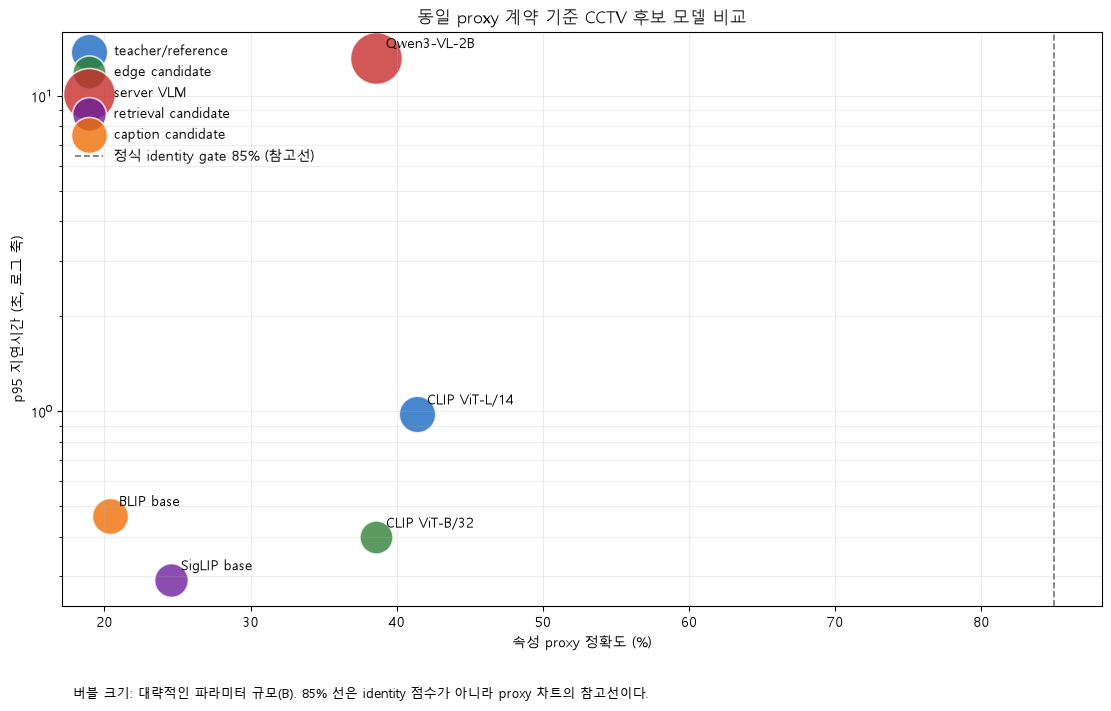

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib import font_manager

project_root = Path.cwd().parent if Path.cwd().name == "experiments" else Path.cwd()
results_root = project_root / "experiments" / "results"
font_candidates = [
    Path("C:/Windows/Fonts/malgun.ttf"),
    Path("C:/Windows/Fonts/NotoSansKR-Regular.ttf"),
]
font_path = next((path for path in font_candidates if path.exists()), None)
if font_path:
    font_manager.fontManager.addfont(str(font_path))
    plt.rcParams["font.family"] = font_manager.FontProperties(fname=str(font_path)).get_name()
plt.rcParams["axes.unicode_minus"] = False
colors = {
    "teacher/reference": "#1565c0",
    "edge candidate": "#2e7d32",
    "server VLM": "#c62828",
    "retrieval candidate": "#6a1b9a",
    "caption candidate": "#ef6c00",
}
fig, ax = plt.subplots(figsize=(11, 7), constrained_layout=True)
chart_rows = globals().get("rows", [])
for row in chart_rows:
    ax.scatter(
        row["속성 proxy 정확도(%)"],
        row["p95 지연(s)"],
        s=500 + row["파라미터(B)"] * 450,
        color=colors[row["역할"]],
        alpha=0.78,
        edgecolor="white",
        linewidth=1.2,
        label=row["역할"],
    )
    ax.annotate(
        row["모델"],
        (row["속성 proxy 정확도(%)"], row["p95 지연(s)"]),
        xytext=(7, 7),
        textcoords="offset points",
        fontsize=10,
    )
ax.axvline(
    85, color="#777777", linestyle="--", linewidth=1.2, label="정식 identity gate 85% (참고선)"
)
ax.set_yscale("log")
ax.set_xlabel("속성 proxy 정확도 (%)")
ax.set_ylabel("p95 지연시간 (초, 로그 축)")
ax.set_title("동일 proxy 계약 기준 CCTV 후보 모델 비교")
ax.grid(True, which="both", alpha=0.22)
handles, labels = ax.get_legend_handles_labels()
unique = dict(zip(labels, handles, strict=True))
ax.legend(unique.values(), unique.keys(), loc="upper left", frameon=False)
ax.text(
    0.01,
    -0.16,
    "버블 크기: 대략적인 파라미터 규모(B). "
    "85% 선은 identity 점수가 아니라 proxy 차트의 참고선이다.",
    transform=ax.transAxes,
    fontsize=9,
)
plt.savefig(results_root / "cctv_model_selection_bubble_chart.png", dpi=180)
plt.savefig(results_root / "cctv_model_selection_bubble_chart.svg")
plt.show()


## Takeaways

- CLIP ViT-L/14가 이번 동일 계약에서 속성 proxy 정확도 **41.40%**로 1위다.
- CLIP ViT-B/32보다 정확도는 **2.81%p** 높지만 p95 지연은 약 **2.5배**다. GPU 서버 teacher/reference라면 이 trade-off를 수용할 수 있다.
- Qwen3-VL-2B는 속성 정확도가 **38.60%**로 비슷하지만 p95가 **13.21초**이고 구조화 출력 유효율도 낮아 실시간 edge teacher로는 부적합하다.
- L/14도 bottom_color **20.0%**, viewpoint **28.9%** 등 세부 속성에는 약점이 있어 distillation만으로 85% identity를 보장할 수 없다.
- 최종 선택은 `CLIP ViT-L/14 teacher/reference -> NanoOWL/경량 student distillation -> 실제 identity track-heldout 검증` 순서로 한다.